<a href="https://colab.research.google.com/github/sambhavi298/LogisticsRegression/blob/main/LogisticsRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["Target"] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (569, 31)

Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'Target']

Data Types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius erro

In [ ]:
print("\nClass Distribution:")
print(df["Target"].value_counts())


Class Distribution:
Target
1    357
0    212
Name: count, dtype: int64


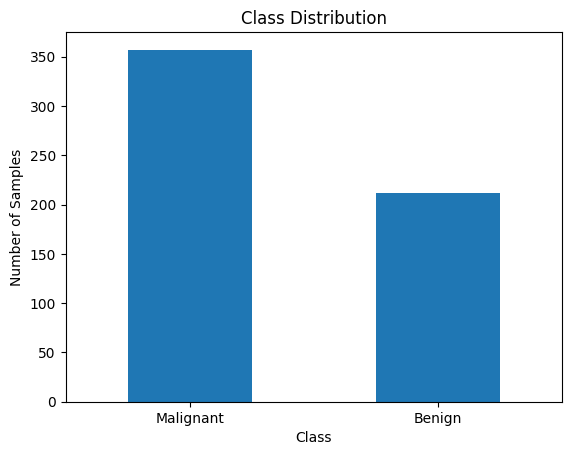

In [ ]:
df["Target"].value_counts().plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"], rotation=0)

plt.show()

In [ ]:
X = df.drop("Target", axis=1)
y = df["Target"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_pred = nb_model.predict(X_test_scaled)

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

In [ ]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("NAIVE BAYES")
print("--------------------")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1 Score :", nb_f1)

NAIVE BAYES
--------------------
Accuracy : 0.9298245614035088
Precision: 0.9444444444444444
Recall   : 0.9444444444444444
F1 Score : 0.9444444444444444


In [ ]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("LOGISTIC REGRESSION")
print("--------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

LOGISTIC REGRESSION
--------------------
Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1 Score : 0.9861111111111112


In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Naive Bayes": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ],

    "Logistic Regression": [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ]
})

comparison

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.929825,0.982456
1,Precision,0.944444,0.986111
2,Recall,0.944444,0.986111
3,F1 Score,0.944444,0.986111


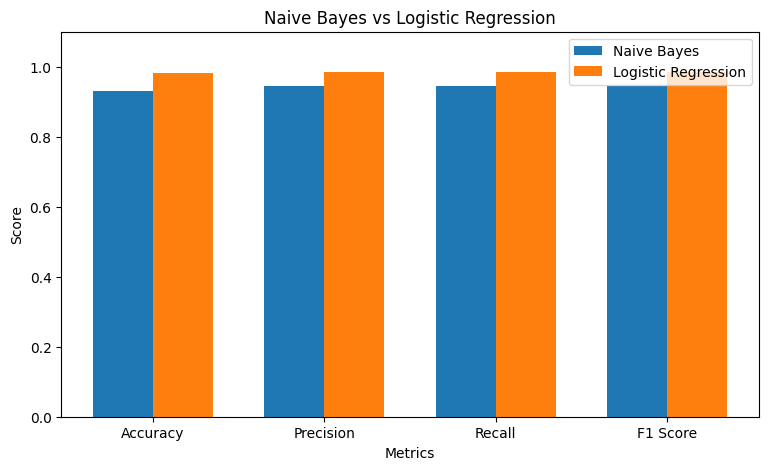

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

nb_scores = [
    nb_accuracy,
    nb_precision,
    nb_recall,
    nb_f1
]

lr_scores = [
    lr_accuracy,
    lr_precision,
    lr_recall,
    lr_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    nb_scores,
    width,
    label="Naive Bayes"
)

plt.bar(
    x + width/2,
    lr_scores,
    width,
    label="Logistic Regression"
)

plt.xlabel("Metrics")
plt.ylabel("Score")
plt.title("Naive Bayes vs Logistic Regression")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()

plt.show()

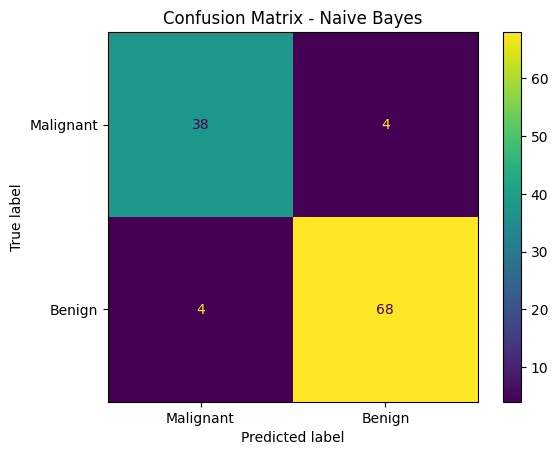

In [ ]:
cm_nb = confusion_matrix(y_test, nb_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Malignant", "Benign"]
).plot()

plt.title("Confusion Matrix - Naive Bayes")
plt.show()

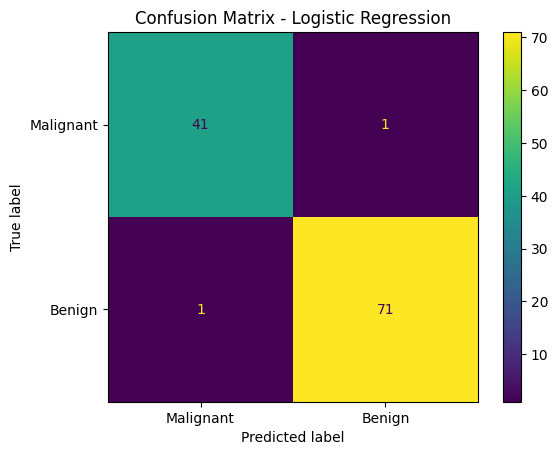

In [ ]:
cm_lr = confusion_matrix(y_test, lr_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Malignant", "Benign"]
).plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
print("Naive Bayes Classification Report")
print(classification_report(
    y_test,
    nb_pred,
    target_names=["Malignant", "Benign"]
))

Naive Bayes Classification Report
              precision    recall  f1-score   support

   Malignant       0.90      0.90      0.90        42
      Benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



In [ ]:
print("Logistic Regression Classification Report")
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Malignant", "Benign"]
))

Logistic Regression Classification Report
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [ ]:
if lr_f1 > nb_f1:
    print("Logistic Regression performed better based on F1 Score.")
elif nb_f1 > lr_f1:
    print("Naive Bayes performed better based on F1 Score.")
else:
    print("Both models have the same F1 Score.")

Logistic Regression performed better based on F1 Score.


<Figure size 800x600 with 0 Axes>

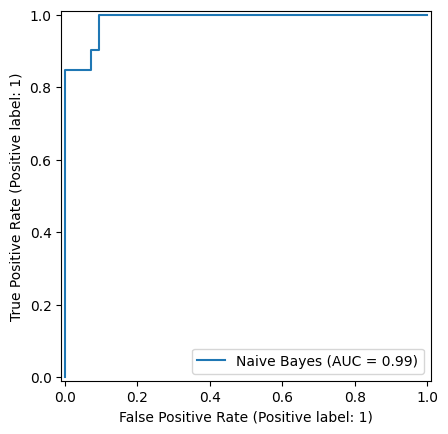

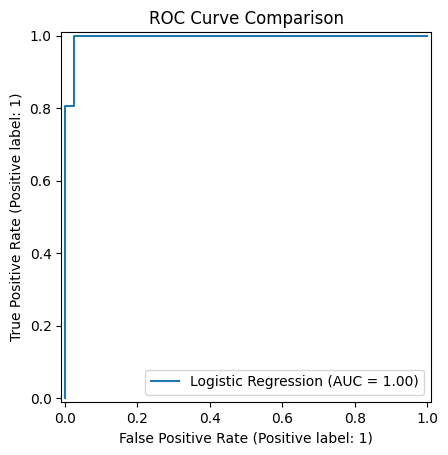

In [ ]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    nb_model,
    X_test_scaled,
    y_test,
    name="Naive Bayes"
)

RocCurveDisplay.from_estimator(
    lr_model,
    X_test_scaled,
    y_test,
    name="Logistic Regression"
)

plt.title("ROC Curve Comparison")
plt.show()